# Assignment 2: Scikit-Learn
1. Classification on Wine · 2. Pipeline + GridSearchCV (SVC) · 3. KMeans elbow on Iris

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_wine, load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.cluster import KMeans

RS = 42

## 1. Classification — Logistic Regression, KNN, Random Forest (Wine)
Stratified 75/25 split. Logistic Regression and KNN are scale-sensitive, so each is wrapped with `StandardScaler`; Random Forest is not.

,Accuracy,F1 (macro)
Model,,
Logistic Regression,1.0000,1.0000
KNN (k=5),0.9333,0.9314
Random Forest,1.0000,1.0000


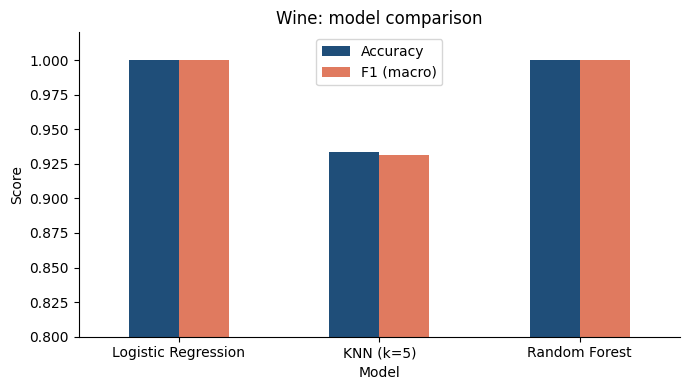

In [2]:
X, y = load_wine(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=RS, stratify=y)

models = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "KNN (k=5)":           Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RS),
}
rows = []
for name, m in models.items():
    pred = m.fit(Xtr, ytr).predict(Xte)
    rows.append({"Model": name, "Accuracy": accuracy_score(yte, pred), "F1 (macro)": f1_score(yte, pred, average="macro")})
results = pd.DataFrame(rows).set_index("Model").round(4)
display(results)

ax = results.plot(kind="bar", figsize=(7, 4), color=["#1F4E79", "#E07A5F"], rot=0, ylim=(0.8, 1.02))
ax.set_title("Wine: model comparison"); ax.set_ylabel("Score"); ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.savefig("wine_model_comparison.png", dpi=200); plt.show()

## 2. Pipeline — StandardScaler + SVC, tuned with GridSearchCV
Grid over `C` and `gamma` (RBF kernel), 5-fold CV on the training set; the test set is only used for the final score.

Best params : {'svc__C': 1, 'svc__gamma': 0.1}
Best CV acc : 0.9923
Test acc    : 0.9778
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       0.95      1.00      0.97        18
     class_2       1.00      0.92      0.96        12

    accuracy                           0.98        45
   macro avg       0.98      0.97      0.98        45
weighted avg       0.98      0.98      0.98        45



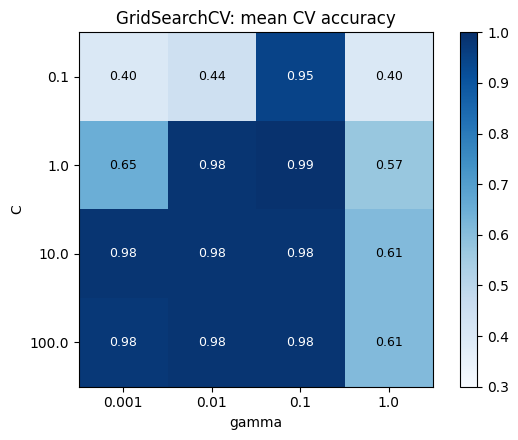

In [3]:
pipe = Pipeline([("scale", StandardScaler()), ("svc", SVC(kernel="rbf"))])
param_grid = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}
grid = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy", n_jobs=-1).fit(Xtr, ytr)

print("Best params :", grid.best_params_)
print(f"Best CV acc : {grid.best_score_:.4f}")
print(f"Test acc    : {grid.score(Xte, yte):.4f}")
print(classification_report(yte, grid.predict(Xte), target_names=load_wine().target_names))

heat = pd.DataFrame(grid.cv_results_)[["param_svc__C","param_svc__gamma","mean_test_score"]]
heat = heat.pivot(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score").astype(float)
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(heat.values, cmap="Blues", vmin=0.3, vmax=1)
ax.set_xticks(range(len(heat.columns)), heat.columns); ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("GridSearchCV: mean CV accuracy")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.65 else "black", fontsize=9)
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.savefig("svc_gridsearch_heatmap.png", dpi=200); plt.show()

## 3. Clustering — KMeans (k = 2 to 8) on Iris, elbow curve

k,2,3,4,5,6,7,8
inertia,152.35,78.85,57.23,46.46,39.04,34.31,30.13


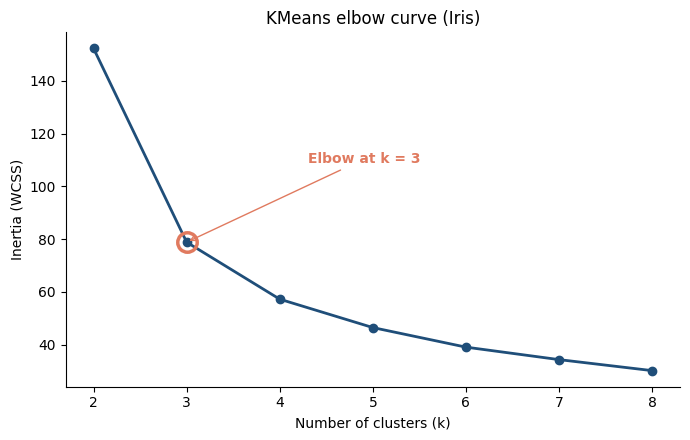

In [4]:
Xi = load_iris().data
ks = list(range(2, 9))
inertia = [KMeans(n_clusters=k, n_init=10, random_state=RS).fit(Xi).inertia_ for k in ks]
display(pd.DataFrame({"k": ks, "inertia": np.round(inertia, 2)}).set_index("k").T)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ks, inertia, marker="o", lw=2, color="#1F4E79")
ax.plot(3, inertia[1], "o", ms=14, mfc="none", mec="#E07A5F", mew=2.5)
ax.annotate("Elbow at k = 3", xy=(3, inertia[1]), xytext=(4.3, inertia[1]+30),
            arrowprops=dict(arrowstyle="->", color="#E07A5F"), color="#E07A5F", fontweight="bold")
ax.set_title("KMeans elbow curve (Iris)"); ax.set_xlabel("Number of clusters (k)"); ax.set_ylabel("Inertia (WCSS)")
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.savefig("iris_elbow_curve.png", dpi=200); plt.show()

## Summary of findings
1. On Wine, Logistic Regression and Random Forest both scored 1.00 accuracy/F1 on the held-out set, while KNN trailed at about 0.93 (accuracy) and 0.93 (macro F1).
2. Scaling matters: the scale-sensitive models (Logistic Regression, KNN) were wrapped in a `StandardScaler` pipeline, which avoids features with large ranges (e.g. proline) dominating.
3. GridSearchCV picked C = 1 and gamma = 0.1 for the scaled SVC, with a 5-fold CV accuracy of about 0.992 and a test accuracy of about 0.978.
4. The Iris elbow curve drops sharply from k = 2 to k = 3 (inertia about 152 to 79) and flattens afterwards, so k = 3 is the best choice, matching the three real species.
5. Caveat: Wine is small (178 samples), so a single test split is noisy. Cross-validated scores would be a safer basis for ranking close models.